# Mini-Project 5 · Verizon
## Part 1 — Select and inspect an option cross-section

**Goal:** choose one trading date and one expiration, identify the market inputs,
plot call prices against strikes, and document quote exclusions. This notebook
stops before estimating either probability model.

**How to use**
1. Put this notebook and the supplied `VZ.csv` in the same folder.
2. Use a Python 3 kernel with `pandas`, `numpy`, `matplotlib`, and `IPython`.
   If needed, install them using `%pip install pandas numpy matplotlib ipython` in a new cell.
3. Run cells from top to bottom. Review the candidate table, then edit the settings cell
   to change the date, expiration, or cleaning thresholds; rerun all cells afterward.
4. Review the exclusion audit and figures. Write your own justification in the final prompts.

**Working example:** 10 March 2025, expiration 14 March 2025. It has four calendar
days to expiration and quotes on both sides of the underlying price. The candidate
table below lets you compare it with alternatives. This is an editable example,
not a requirement to use this date.

Data source: the course-supplied `VZ.csv` (Brightspace). No external market data is fetched.

In [1]:
from pathlib import Path
import hashlib
import json
import platform
import warnings
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

pd.set_option('display.max_rows', 70)
pd.set_option('display.max_columns', 20)
pd.set_option('display.width', 150)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.grid': True,
                     'grid.alpha': 0.18, 'font.size': 10})
print(f'Python {platform.python_version()} | pandas {pd.__version__} | '
      f'NumPy {np.__version__} | matplotlib {matplotlib.__version__}')

Python 3.14.7 | pandas 3.0.6 | NumPy 2.5.3 | matplotlib 3.11.2


### 1. Settings — the choices you can change

Dollar prices are **per share**, not per 100-share contract. A midquote is
\(C_{mid}=(bid+ask)/2\), not a transaction price.

The starting rules require a positive bid and midpoint of at least $0.05,
an absolute spread no larger than $0.30, and a spread/midpoint ratio no larger
than 50%. The absolute rule removes expensive uncertainty; the relative rule
removes uncertainty that is large compared with the option premium.
These cutoffs are judgments, not universal market standards.

We do not automatically remove zero-volume or zero-open-interest quotes:
an untraded option may still have an informative two-sided quote. We do not
choose observations based on either model's eventual fit.

In [2]:
CSV_PATH = Path('VZ.csv')  # Change this if your data is in another folder.
SELECTED_DATE = '2025-03-10'
SELECTED_EXPIRY = '2025-03-14'
MIN_CALENDAR_DAYS = 3

MIN_MID = 0.05
MAX_ABS_SPREAD = 0.30
MAX_REL_SPREAD = 0.50
EPS = 1e-9  # Avoid rejecting $0.30 because of floating-point rounding.

# Time convention: actual calendar days divided by 365 by default.
# 'vendor' uses the file's years column instead; inspect the discrepancy below.
TIME_SOURCE = 'calendar'  # 'calendar' or 'vendor'
RATE_OVERRIDE = None  # Annual continuously compounded decimal, e.g. 0.045.
RATE_NOTE = 'CSV rate; treated as annual continuously compounded, convention unverified'

# Optional manual exclusions: {strike: 'your specific reason'}.
# Record reasons before fitting, and justify them in your report.
MANUAL_EXCLUSIONS = {}
EXPORT_FILES = False  # True writes review tables, figures and metadata to part1_outputs/.

### 2. Read the file and understand its columns

| CSV column | Use here | Caution |
|---|---|---|
| `tradingDate` | Observation date | Do not use processing `timestamp` as the trading date. |
| `okey_date` | Expiration date | One terminal distribution requires one expiration. |
| `okey_cp`, `okey_xx` | Call/put flag; strike | We use calls only in Part 1. |
| `bidPrc`, `askPrc` | Observed option quotes | We construct our own midpoint. |
| `uBid`, `uAsk` | Underlying quotes | Their midpoint is our stock-price snapshot. |
| `uSrCls`, `uClose` | Alternative underlying reference prices | Displayed for comparison; may reflect a different snapshot. |
| `rate` | Supplied interest-rate input | Interpret as an annual decimal; compounding needs confirmation. |
| `years` | Supplied model time input | Not assumed equal to calendar days / 365. |
| `ddiv`, `sdiv` | Vendor dividend-related fields | Units, timing and meaning are not documented in the CSV. |
| `openInterest`, `prtVolume` | Liquidity context | Not mandatory positive-value filters. |
| `srPrc`, `srVol`, Greeks | Vendor model-derived fields | Not used as observed option prices or calibration targets. |

The CSV has no accompanying data dictionary. Column interpretations above are
working conventions based on the labels and internal comparisons; confirm any
uncertain conventions with the course materials or instructor.

In [3]:
if not CSV_PATH.is_file():
    raise FileNotFoundError(f'Place VZ.csv beside this notebook or edit CSV_PATH. Current folder: {Path.cwd()}')

raw = pd.read_csv(CSV_PATH)
required = ['tradingDate', 'okey_date', 'okey_cp', 'okey_xx', 'bidPrc', 'askPrc',
            'uBid', 'uAsk', 'rate', 'years']
missing_columns = sorted(set(required) - set(raw.columns))
if missing_columns:
    raise ValueError(f'Missing required columns: {missing_columns}')

quotes = raw.rename(columns={'tradingDate': 'trade_date', 'okey_date': 'expiry',
                            'okey_cp': 'option_type', 'okey_xx': 'strike',
                            'bidPrc': 'bid', 'askPrc': 'ask'}).copy()
quotes['source_row'] = np.arange(len(quotes)) + 2  # CSV line including header.
for c in ['trade_date', 'expiry']:
    quotes[c] = pd.to_datetime(quotes[c], errors='coerce').dt.normalize()
numeric = ['strike', 'bid', 'ask', 'uBid', 'uAsk', 'uSrCls', 'uClose',
           'rate', 'years', 'ddiv', 'sdiv', 'openInterest', 'prtVolume']
for c in numeric:
    if c in quotes:
        quotes[c] = pd.to_numeric(quotes[c], errors='coerce')
quotes['option_type'] = quotes['option_type'].astype('string').str.strip().str.lower()
quotes['calendar_days'] = (quotes['expiry'] - quotes['trade_date']).dt.days
quotes['mid'] = (quotes['bid'] + quotes['ask']) / 2
quotes['spread'] = quotes['ask'] - quotes['bid']
quotes['relative_spread'] = quotes['spread'] / quotes['mid'].where(quotes['mid'] > 0)
quotes['spot_quote_mid'] = (quotes['uBid'] + quotes['uAsk']) / 2

file_sha256 = hashlib.sha256(CSV_PATH.read_bytes()).hexdigest()
print(f'File: {CSV_PATH.name} | rows: {len(raw):,} | columns: {len(raw.columns)}')
print(f'Trading dates: {quotes.trade_date.min().date()} to {quotes.trade_date.max().date()}')
print('Option counts:', quotes.option_type.value_counts().to_dict())
print('SHA-256:', file_sha256)
display(quotes[['source_row', 'trade_date', 'expiry', 'option_type', 'strike',
                'bid', 'ask', 'spot_quote_mid', 'rate', 'years']].head(6))
display(quotes[required_numeric := ['strike', 'bid', 'ask', 'rate', 'years']]
        .isna().sum().rename('Missing / nonnumeric values').to_frame())
print('Unparseable dates:', int(quotes[['trade_date', 'expiry']].isna().any(axis=1).sum()))

File: VZ.csv | rows: 20,318 | columns: 60
Trading dates: 2025-01-02 to 2025-12-31
Option counts: {'put': 10159, 'call': 10159}
SHA-256: 1acace3fb2a5bdd52bd1bd3866e8662da0245124eadc0aecbbaa353473182866
Unparseable dates: 0


,source_row,trade_date,expiry,option_type,strike,bid,ask,spot_quote_mid,rate,years
0,2,2025-01-02,2025-01-03,put,25.0,0.00,0.05,40.195,0.0491,0.0036
1,3,2025-01-02,2025-01-03,call,25.0,13.10,17.30,40.195,0.0491,0.0036
2,4,2025-01-02,2025-01-03,put,30.0,0.00,0.53,40.195,0.0491,0.0036
3,5,2025-01-02,2025-01-03,call,30.0,8.10,12.30,40.195,0.0491,0.0036
4,6,2025-01-02,2025-01-03,put,31.0,0.00,0.53,40.195,0.0491,0.0036
5,7,2025-01-02,2025-01-03,call,31.0,7.15,11.15,40.195,0.0491,0.0036


,Missing / nonnumeric values
strike,0
bid,0
ask,0
rate,0
years,0


### 3. Compare eligible date–expiration pairs

The assignment requires **at least three calendar days** remaining. This check
uses expiration date minus trading date and does not depend on the vendor's
`years` convention. We keep one expiration even if a date offers multiple ones.

The ranking below counts quotes passing the initial rules. More retained
strikes are useful, but a large count alone does not establish an informative
or trustworthy distribution. Check strike coverage near the stock price too.

In [4]:
def quality_flags(frame):
    finite_quote = np.isfinite(frame[['strike', 'bid', 'ask']]).all(axis=1)
    return pd.DataFrame({
        'nonfinite strike/bid/ask': ~finite_quote,
        'nonpositive strike': frame.strike.le(0),
        'negative bid or ask': frame.bid.lt(0) | frame.ask.lt(0),
        'crossed market (ask < bid)': frame.spread.lt(-EPS),
        'zero bid': frame.bid.eq(0),
        'midpoint below minimum': frame.mid.lt(MIN_MID - EPS),
        'absolute spread above limit': frame.spread.gt(MAX_ABS_SPREAD + EPS),
        'relative spread above limit': frame.relative_spread.gt(MAX_REL_SPREAD + EPS),
    }, index=frame.index).fillna(False)

eligible = quotes.loc[(quotes.option_type == 'call') &
                      quotes.calendar_days.ge(MIN_CALENDAR_DAYS)].copy()
eligible['passes_rules'] = ~quality_flags(eligible).any(axis=1)
eligible['kept_strike'] = eligible.strike.where(eligible.passes_rules)
eligible['near_spot_kept'] = (eligible.passes_rules &
                             ((eligible.strike / eligible.spot_quote_mid - 1).abs() <= 0.05))
candidates = (eligible.groupby(['trade_date', 'expiry'], as_index=False)
    .agg(calendar_days=('calendar_days', 'first'), available_calls=('strike', 'size'),
         retained_by_rules=('passes_rules', 'sum'), near_spot_retained=('near_spot_kept', 'sum'),
         retained_K_min=('kept_strike', 'min'), retained_K_max=('kept_strike', 'max'),
         spot=('spot_quote_mid', 'median'))
    .sort_values(['retained_by_rules', 'near_spot_retained', 'trade_date'],
                 ascending=[False, False, True]).reset_index(drop=True))
if candidates.empty:
    raise ValueError('No eligible calls. Check the data and minimum calendar days.')
print(f'{len(candidates)} eligible date–expiration pairs. Top 15 under current rules:')
display(candidates.head(15).round(4))
print('Eligible calendar-day horizons:', sorted(eligible.calendar_days.unique().tolist()))

98 eligible date–expiration pairs. Top 15 under current rules:
Eligible calendar-day horizons: [3, 4]


<ipython-input-1-986dc7675c64>:30: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(candidates.head(15).round(4))


,trade_date,expiry,calendar_days,available_calls,retained_by_rules,near_spot_retained,retained_K_min,retained_K_max,spot
0,2025-03-10,2025-03-14,4,40,29,9,25.0,48.5,46.545
1,2025-03-31,2025-04-04,4,40,24,8,25.0,47.0,45.405
2,2025-03-04,2025-03-07,3,42,24,7,25.0,44.0,42.885
3,2025-02-24,2025-02-28,4,39,23,7,25.0,44.5,43.365
4,2025-03-17,2025-03-21,4,42,23,7,31.0,45.0,43.715
5,2025-08-12,2025-08-15,3,41,23,6,24.0,44.0,43.225
6,2025-03-03,2025-03-07,4,42,22,7,29.0,45.0,43.795
7,2025-08-26,2025-08-29,3,40,21,6,25.0,44.5,43.975
8,2025-01-27,2025-01-31,4,40,20,6,31.0,41.5,40.645
9,2025-02-18,2025-02-21,3,41,20,5,23.0,41.5,41.115


### 4. Fix one cross-section and identify its market inputs

We use \(S_0=(uBid+uAsk)/2\), aligned with the quote-based option prices. We display
the alternatives rather than silently replacing the quote snapshot with `uClose`.
Underlying inputs should be consistent across the selected contracts; conflicting
values trigger a warning for review.

**Time:** the default is \(T=(expiration-trading\ date)/365\), an explicit ACT/365
date-based approximation. It does not account for intraday timing. The file's
`years` can differ materially at these very short horizons. Inspect both and
confirm the intended course convention before fitting; keep the same choice for
both models.

**Interest rate:** use the selected chain's median `rate` as an annual decimal,
with continuous compounding as an explicit working assumption for later
\(e^{-rT}\) discounting. No rate is estimated from these call prices in Part 1.
An override requires a source note. Missing/inconsistent inputs are not silently
replaced by an arbitrary market rate.

In [5]:
trade_date, expiry = pd.Timestamp(SELECTED_DATE), pd.Timestamp(SELECTED_EXPIRY)
chain = quotes.loc[(quotes.trade_date == trade_date) & (quotes.expiry == expiry) &
                   (quotes.option_type == 'call')].sort_values('strike').copy()
if chain.empty:
    raise ValueError('Selected call chain is empty. Choose a pair from candidates.')
calendar_days = (expiry - trade_date).days
if calendar_days < MIN_CALENDAR_DAYS:
    raise ValueError('Selected expiration fails the minimum calendar-day requirement.')
if chain.strike.duplicated().any():
    raise ValueError('Duplicate strikes in this chain: review snapshots before proceeding.')

def checked_median(column):
    values = chain[column].replace([np.inf, -np.inf], np.nan).dropna()
    if values.empty:
        raise ValueError(f'No usable {column} in selected chain.')
    if values.max() - values.min() > 1e-8:
        warnings.warn(f'{column} differs across contracts: inspect its min/max before using the median.')
    return float(values.median())

S0 = checked_median('spot_quote_mid')
if S0 <= 0 or (chain.uAsk < chain.uBid).any() or (chain.uBid <= 0).any():
    raise ValueError('Invalid underlying quotes: review this chain.')
T_calendar = calendar_days / 365.0
T_vendor = checked_median('years')
if TIME_SOURCE not in {'calendar', 'vendor'}:
    raise ValueError("TIME_SOURCE must be 'calendar' or 'vendor'.")
T = T_calendar if TIME_SOURCE == 'calendar' else T_vendor
r = checked_median('rate') if RATE_OVERRIDE is None else float(RATE_OVERRIDE)
if not (np.isfinite(T) and T > 0 and np.isfinite(r)):
    raise ValueError('T must be positive and finite; r must be finite.')

input_columns = [c for c in ['uBid', 'uAsk', 'spot_quote_mid', 'uSrCls', 'uClose',
                             'rate', 'years', 'ddiv', 'sdiv'] if c in chain]
display(chain[input_columns].agg(['min', 'median', 'max']).T.round(8))
inputs = pd.DataFrame({
    'Input': ['Trading date', 'Expiration', 'Calendar days remaining', 'S0 (quote midpoint)',
              'T, ACT/365', 'T, vendor years', 'T used', 'Time source',
              'r used, annual decimal', 'r used, annual percent', 'Discount factor exp(-rT)'],
    'Value': [str(trade_date.date()), str(expiry.date()), calendar_days, S0,
              T_calendar, T_vendor, T, TIME_SOURCE, r, 100*r, np.exp(-r*T)]})
display(inputs)
print(f'Vendor T corresponds to {365*T_vendor:.4f} calendar-equivalent days; date difference is {calendar_days}.')
print('Rate convention:', RATE_NOTE)
print('All available strikes:', chain.strike.tolist())

Vendor T corresponds to 5.1525 calendar-equivalent days; date difference is 4.
Rate convention: CSV rate; treated as annual continuously compounded, convention unverified
All available strikes: [25.0, 30.0, 31.0, 32.0, 33.0, 34.0, 35.0, 36.0, 36.5, 37.0, 37.5, 38.0, 38.5, 39.0, 39.5, 40.0, 40.5, 41.0, 41.5, 42.0, 42.5, 43.0, 43.5, 44.0, 44.5, 45.0, 45.5, 46.0, 46.5, 47.0, 47.5, 48.0, 48.5, 49.0, 49.5, 50.0, 51.0, 52.0, 53.0, 55.0]


,min,median,max
uBid,46.540000,46.540000,46.540000
uAsk,46.550000,46.550000,46.550000
spot_quote_mid,46.545000,46.545000,46.545000
uSrCls,46.545000,46.545000,46.545000
uClose,46.545000,46.545000,46.545000
rate,0.044504,0.044504,0.044504
years,0.014116,0.014116,0.014116
ddiv,0.000000,0.000000,0.000000
sdiv,-0.018376,-0.018376,-0.018376


,Input,Value
0,Trading date,2025-03-10
1,Expiration,2025-03-14
2,Calendar days remaining,4
3,S0 (quote midpoint),46.545
4,"T, ACT/365",0.010959
5,"T, vendor years",0.014116
6,T used,0.010959
7,Time source,calendar
8,"r used, annual decimal",0.044504
9,"r used, annual percent",4.45036


### 5. Plot the observed call quotes before cleaning

Each marker is a midpoint; its vertical interval runs from bid to ask. Long
intervals mean uncertain prices. The dotted vertical line marks the underlying
price. Do not mistake `srPrc` (a vendor model output) for an observed market price.

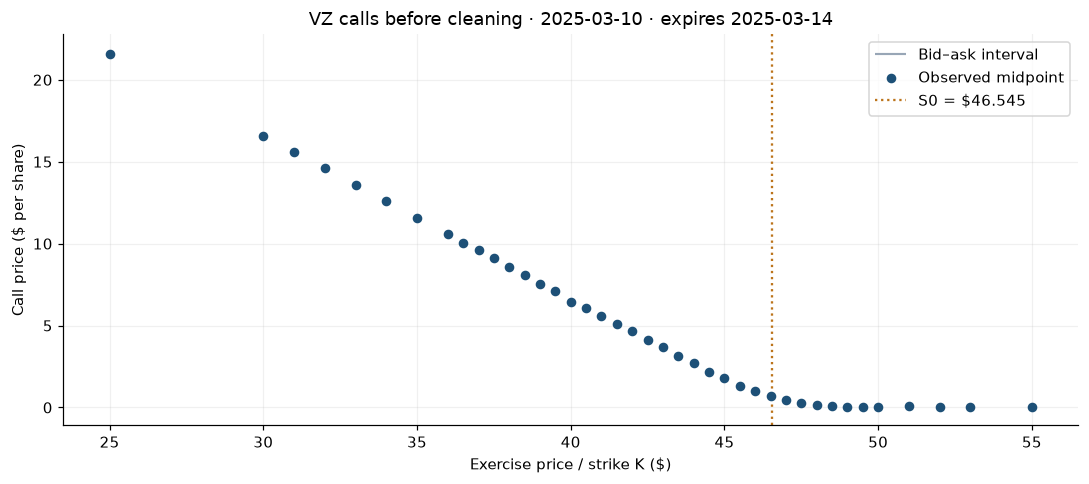

In [6]:
fig_raw, ax = plt.subplots(figsize=(10, 4.5))
plot_raw = chain.loc[np.isfinite(chain[['strike', 'bid', 'ask', 'mid']]).all(axis=1)]
ax.vlines(plot_raw.strike, plot_raw.bid, plot_raw.ask, color='#98a6b6', lw=1.4, label='Bid–ask interval')
ax.scatter(plot_raw.strike, plot_raw.mid, s=28, color='#1d5077', label='Observed midpoint', zorder=3)
ax.axvline(S0, color='#bc741b', ls=':', label=f'S0 = ${S0:.3f}')
ax.set(xlabel='Exercise price / strike K ($)', ylabel='Call price ($ per share)',
       title=f'VZ calls before cleaning · {trade_date.date()} · expires {expiry.date()}')
ax.legend(); fig_raw.tight_layout(); plt.show()

### 6. Apply the rules and retain a full audit

One quote can fail more than one rule, so individual rule counts may add to more
than the number excluded. The audit retains every original strike and all reasons.
Manual exclusions are additional choices you must explain.

In [7]:
flags = quality_flags(chain)
unknown_strikes = set(MANUAL_EXCLUSIONS) - set(chain.strike)
if unknown_strikes:
    raise ValueError(f'Manual exclusion strikes absent from chain: {unknown_strikes}')
if any(not isinstance(reason, str) or not reason.strip() for reason in MANUAL_EXCLUSIONS.values()):
    raise ValueError('Every manual exclusion must have a nonempty reason.')
manual_reason = chain.strike.map(MANUAL_EXCLUSIONS).fillna('')
chain['exclusion_reason'] = flags.apply(lambda row: '; '.join(row.index[row]), axis=1)
for idx in chain.index[manual_reason.ne('')]:
    existing = chain.at[idx, 'exclusion_reason']
    chain.at[idx, 'exclusion_reason'] = (existing + '; ' if existing else '') + 'manual: ' + manual_reason.at[idx]
chain['retained'] = chain.exclusion_reason.eq('')
clean = chain.loc[chain.retained].copy()
excluded = chain.loc[~chain.retained].copy()
if clean.empty:
    raise ValueError('No quotes survived. Review your selected date and thresholds.')
if len(clean) < 8:
    warnings.warn('Few retained strikes: estimating a flexible mixture may be unstable.')

audit_columns = ['source_row', 'strike', 'bid', 'ask', 'mid', 'spread', 'relative_spread',
                 'openInterest', 'prtVolume', 'retained', 'exclusion_reason']
audit_columns = [c for c in audit_columns if c in chain]
audit = chain[audit_columns].copy()
rule_counts = flags.sum().rename('Quotes failing rule').to_frame()
rule_counts.loc['manual exclusion'] = int(manual_reason.ne('').sum())
display(rule_counts)
print(f'Retained {len(clean)} of {len(chain)} calls; excluded {len(excluded)}.')
print('Retained strikes:', clean.strike.tolist())
display(audit.round({'mid': 4, 'spread': 4, 'relative_spread': 4}))

Retained 29 of 40 calls; excluded 11.
Retained strikes: [25.0, 30.0, 31.0, 32.0, 33.0, 35.0, 36.0, 36.5, 37.0, 37.5, 38.0, 38.5, 39.0, 40.5, 41.0, 41.5, 42.0, 42.5, 43.0, 43.5, 44.5, 45.0, 45.5, 46.0, 46.5, 47.0, 47.5, 48.0, 48.5]


,Quotes failing rule
nonfinite strike/bid/ask,0
nonpositive strike,0
negative bid or ask,0
crossed market (ask < bid),0
zero bid,5
midpoint below minimum,5
absolute spread above limit,4
relative spread above limit,7
manual exclusion,0


,source_row,strike,bid,ask,mid,spread,relative_spread,openInterest,prtVolume,retained,exclusion_reason
3565,3567,25.0,21.45,21.70,21.575,0.25,0.0116,4,2,True,
3567,3569,30.0,16.50,16.70,16.600,0.20,0.0120,0,0,True,
3569,3571,31.0,15.45,15.75,15.600,0.30,0.0192,0,0,True,
3571,3573,32.0,14.45,14.75,14.600,0.30,0.0205,0,0,True,
3573,3575,33.0,13.50,13.70,13.600,0.20,0.0147,0,0,True,
3575,3577,34.0,12.40,12.75,12.575,0.35,0.0278,0,0,False,absolute spread above limit
3577,3579,35.0,11.40,11.70,11.550,0.30,0.0260,13,0,True,
3579,3581,36.0,10.50,10.70,10.600,0.20,0.0189,1,0,True,
3581,3583,36.5,9.90,10.20,10.050,0.30,0.0299,0,0,True,
3583,3585,37.0,9.45,9.75,9.600,0.30,0.0313,0,0,True,


### 7. Compare spreads and visualize the retained observations

Panel 1 shows retained versus excluded prices with quote intervals. Panels 2 and 3
show the absolute and relative spreads against the cutoffs. A small dollar spread
can still be large relative to a cheap out-of-the-money option.

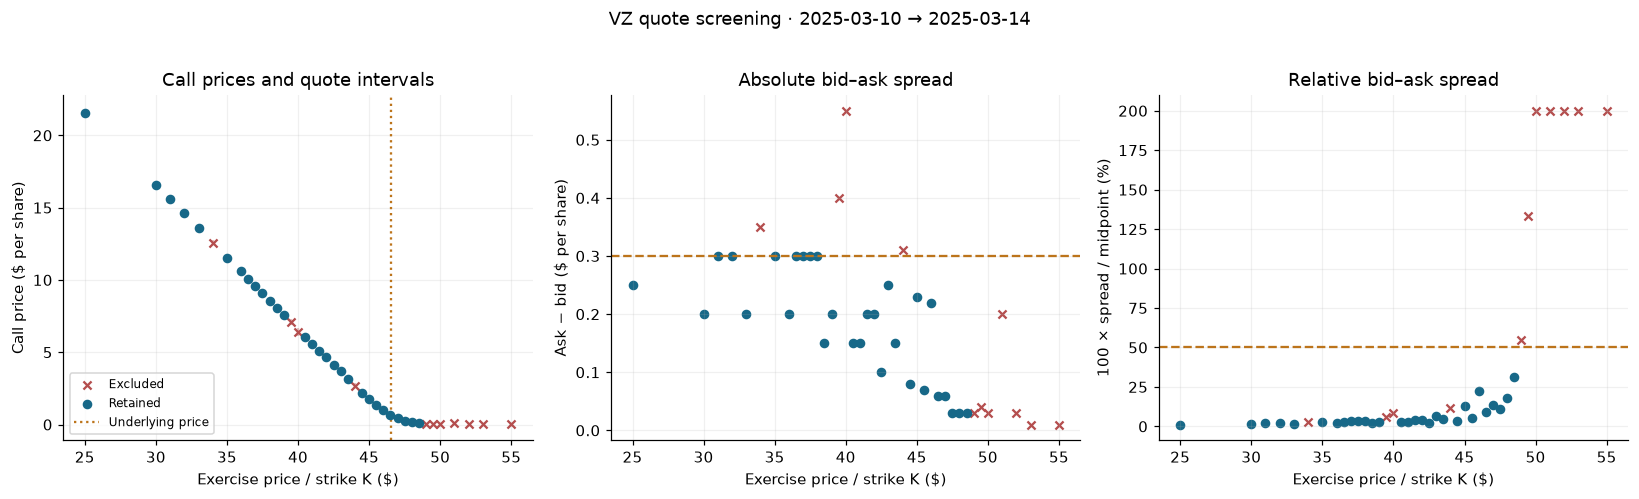

In [8]:
fig_clean, axes = plt.subplots(1, 3, figsize=(15, 4.4))
for keep, label, color, marker in [(False, 'Excluded', '#b44e4e', 'x'),
                                  (True, 'Retained', '#176888', 'o')]:
    d = chain.loc[chain.retained.eq(keep)]
    axes[0].vlines(d.strike, d.bid, d.ask, color=color, alpha=0.35)
    axes[0].scatter(d.strike, d.mid, c=color, marker=marker, s=28, label=label, zorder=3)
    axes[1].scatter(d.strike, d.spread, c=color, marker=marker, s=28)
    axes[2].scatter(d.strike, 100*d.relative_spread, c=color, marker=marker, s=28)
axes[0].axvline(S0, color='#bc741b', ls=':', label='Underlying price')
axes[0].set(title='Call prices and quote intervals', ylabel='Call price ($ per share)')
axes[0].legend(fontsize=8)
axes[1].axhline(MAX_ABS_SPREAD, color='#bc741b', ls='--', label='Absolute cutoff')
axes[1].set(title='Absolute bid–ask spread', ylabel='Ask − bid ($ per share)')
axes[2].axhline(100*MAX_REL_SPREAD, color='#bc741b', ls='--', label='Relative cutoff')
axes[2].set(title='Relative bid–ask spread', ylabel='100 × spread / midpoint (%)')
for ax in axes:
    ax.set_xlabel('Exercise price / strike K ($)')
fig_clean.suptitle(f'VZ quote screening · {trade_date.date()} → {expiry.date()}', y=1.02)
fig_clean.tight_layout(); plt.show()

### 8. Sanity checks — review flags, do not automatically delete them

For a common expiry, calls should generally decrease and be convex in strike.
We check adjacent midpoint slopes using **actual strike spacings** (the grid is
not equally spaced). Midpoints can violate these properties even when trades
inside the quoted intervals could satisfy them, so a flag is not proof of an
executable arbitrage.

For American calls we also flag \(C_{mid}<\max(S_0-K,0)\) and \(C_{mid}>S_0\),
allowing one cent for quote noise. Do not apply a European no-dividend lower
bound to these dividend-paying American contracts without further assumptions.
The selected snapshot and rounding can matter for a short maturity.

In [9]:
K = clean.strike.to_numpy(dtype=float)
C_mid = clean.mid.to_numpy(dtype=float)
slopes = np.diff(C_mid) / np.diff(K)
monotonic_pairs = pd.DataFrame({'K_left': K[:-1], 'K_right': K[1:],
                                'price_change': np.diff(C_mid), 'slope': slopes})
monotonic_flags = monotonic_pairs.loc[monotonic_pairs.price_change.gt(0.01 + EPS)]
convexity_checks = pd.DataFrame({'K_center': K[1:-1],
                                 'left_slope': slopes[:-1], 'right_slope': slopes[1:]})
convexity_checks['slope_change'] = convexity_checks.right_slope - convexity_checks.left_slope
convexity_flags = convexity_checks.loc[convexity_checks.slope_change.lt(-0.01 - EPS)]
bound_flags = clean.loc[(clean.mid < np.maximum(S0-clean.strike, 0)-0.01-EPS) |
                        (clean.mid > S0+0.01+EPS), ['strike', 'mid', 'bid', 'ask']]
print(f'Midpoint increases > $0.01: {len(monotonic_flags)}')
display(monotonic_flags)
print(f'Convexity flags (slope drop > 0.01): {len(convexity_flags)}')
display(convexity_flags)
print(f'American midpoint bound flags, $0.01 tolerance: {len(bound_flags)}')
display(bound_flags)
print(f'Retained below / at / above S0: {(K<S0).sum()} / {(K==S0).sum()} / {(K>S0).sum()}')
print(f'Retained moneyness K/S0: {K.min()/S0:.3f} to {K.max()/S0:.3f}')

Midpoint increases > $0.01: 0
Convexity flags (slope drop > 0.01): 9
American midpoint bound flags, $0.01 tolerance: 0
Retained below / at / above S0: 25 / 0 / 4
Retained moneyness K/S0: 0.537 to 1.042


,K_left,K_right,price_change,slope


,K_center,left_slope,right_slope,slope_change
3,33.0,-1.000000,-1.025,-0.025000
5,36.0,-0.950000,-1.100,-0.150000
7,37.0,-0.900000,-1.000,-0.100000
8,37.5,-1.000000,-1.100,-0.100000
10,38.5,-0.950000,-1.050,-0.100000
12,40.5,-0.983333,-1.000,-0.016667
15,42.0,-0.900000,-1.100,-0.200000
17,43.0,-0.850000,-1.100,-0.250000
20,45.0,-0.790000,-0.920,-0.130000


,strike,mid,bid,ask


### 9. Dividend and model notes to carry into Parts 2–3

- The CSV's `ddiv` and `sdiv` are displayed as raw vendor fields. **A zero `ddiv`
  is not independent confirmation that no ex-dividend event occurs before expiry.**
  Confirm the schedule and field definitions before selecting a dividend assumption.
  Do not interpret `sdiv` automatically as an annual dividend yield.
- Later, European pricing discounts expected terminal payoffs. If you constrain
  the risk-neutral terminal mean using spot and carry, the dividend treatment must
  be explicit. Part 1 does not impose a forward mean or fit a dividend yield.
- These are American options. Early exercise, particularly around ex-dividend
  dates, can affect a European fit. Tight spreads alone do not remove this issue.
- Very short horizons and missing cheap tail quotes limit what the data reveal
  about distribution tails. Deep in-the-money prices mostly reflect intrinsic
  value; many such strikes do not necessarily identify the density well.
- Implied distributions in the later models are risk-neutral pricing distributions;
  their probabilities are not automatically real-world forecasts.

### 10. Prepare the same observations for both later models

`calibration_data` contains the retained calls; `K`, `C_obs`, `S0`, `T`, and `r`
are ready to reuse. The two models should use exactly the same retained rows.
No option model is fitted here. Set `EXPORT_FILES = True` to write the audit,
clean data, candidate table, figures, and assumptions to `part1_outputs/`.

In [10]:
calibration_data = clean[['trade_date', 'expiry', 'strike', 'bid', 'ask', 'mid',
                          'spread', 'relative_spread', 'source_row']].copy()
calibration_data['S0'] = S0
calibration_data['T'] = T
calibration_data['r'] = r
K = calibration_data.strike.to_numpy(dtype=float)
C_obs = calibration_data.mid.to_numpy(dtype=float)

metadata = {
    'source_file': CSV_PATH.name, 'source_sha256': file_sha256,
    'trade_date': str(trade_date.date()), 'expiry': str(expiry.date()),
    'calendar_days': calendar_days, 'S0': S0, 'spot_source': '(uBid + uAsk) / 2',
    'T': T, 'time_source': TIME_SOURCE, 'T_calendar': T_calendar, 'T_vendor': T_vendor,
    'r': r, 'rate_note': RATE_NOTE, 'rate_override': RATE_OVERRIDE,
    'dividend_assumption': 'Unresolved: verify schedule and CSV field conventions before fitting',
    'price_source': '(bidPrc + askPrc) / 2',
    'min_mid': MIN_MID, 'max_absolute_spread': MAX_ABS_SPREAD,
    'max_relative_spread': MAX_REL_SPREAD,
    'manual_exclusions': {str(k): v for k, v in MANUAL_EXCLUSIONS.items()},
    'available_calls': len(chain), 'retained_calls': len(clean),
    'strike_min': float(K.min()), 'strike_max': float(K.max()),
}
assert calibration_data.strike.is_unique
assert np.isfinite(calibration_data[['strike','bid','ask','mid','S0','T','r']]).all().all()
assert (calibration_data.ask >= calibration_data.bid - EPS).all()
display(calibration_data.round(6))
if EXPORT_FILES:
    out = Path('part1_outputs')
    out.mkdir(exist_ok=True)
    calibration_data.to_csv(out / 'VZ_part1_clean_calls.csv', index=False)
    audit.to_csv(out / 'VZ_part1_quote_audit.csv', index=False)
    candidates.to_csv(out / 'VZ_part1_candidates.csv', index=False)
    (out / 'VZ_part1_inputs.json').write_text(json.dumps(metadata, indent=2))
    fig_raw.savefig(out / 'VZ_part1_observed_calls.png', dpi=180, bbox_inches='tight')
    fig_clean.savefig(out / 'VZ_part1_screening.png', dpi=180, bbox_inches='tight')
    print('Exported tables, assumptions and plots to', out.resolve())
else:
    print('Exports disabled; all tables and plots remain visible in this notebook.')

Exports disabled; all tables and plots remain visible in this notebook.


<ipython-input-1-61599fee23cd>:26: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(calibration_data.round(6))


,trade_date,expiry,strike,bid,ask,mid,spread,relative_spread,source_row,S0,T,r
3565,2025-03-10,2025-03-14,25.0,21.45,21.70,21.575,0.25,0.011587,3567,46.545,0.010959,0.044504
3567,2025-03-10,2025-03-14,30.0,16.50,16.70,16.600,0.20,0.012048,3569,46.545,0.010959,0.044504
3569,2025-03-10,2025-03-14,31.0,15.45,15.75,15.600,0.30,0.019231,3571,46.545,0.010959,0.044504
3571,2025-03-10,2025-03-14,32.0,14.45,14.75,14.600,0.30,0.020548,3573,46.545,0.010959,0.044504
3573,2025-03-10,2025-03-14,33.0,13.50,13.70,13.600,0.20,0.014706,3575,46.545,0.010959,0.044504
3577,2025-03-10,2025-03-14,35.0,11.40,11.70,11.550,0.30,0.025974,3579,46.545,0.010959,0.044504
3579,2025-03-10,2025-03-14,36.0,10.50,10.70,10.600,0.20,0.018868,3581,46.545,0.010959,0.044504
3581,2025-03-10,2025-03-14,36.5,9.90,10.20,10.050,0.30,0.029851,3583,46.545,0.010959,0.044504
3583,2025-03-10,2025-03-14,37.0,9.45,9.75,9.600,0.30,0.031250,3585,46.545,0.010959,0.044504
3585,2025-03-10,2025-03-14,37.5,8.95,9.25,9.100,0.30,0.032967,3587,46.545,0.010959,0.044504


### 11. Your Part 1 explanation

The next cell generates a **factual summary**, not the economic justification for
your choices. Use it to check your report and answer these questions in your own words:

1. Why is this date–expiration pair useful compared with the other candidates?
2. Why are these spread limits appropriate, and what information might they remove?
3. What do the stock-price and time-convention comparisons show?
4. Are any shape or bound flags concerning? Do they require further investigation?
5. Which rate and dividend conventions still need confirmation before calibration?

**Your rationale:** _Replace this line with your own explanation after reviewing the outputs._

In [11]:
display(Markdown(
    f'**Current factual summary.** The selected cross-section is {trade_date.date()}, '
    f'with expiration {expiry.date()} ({calendar_days} calendar days remaining). '
    f'The underlying quote midpoint is **${S0:.3f}**. The working interest rate is '
    f'**{100*r:.4f}%** per year and the chosen time input is **{T:.8f} years** '
    f'using `{TIME_SOURCE}`. We retain **{len(clean)} of {len(chain)}** call quotes, '
    f'with strikes from **${K.min():g} to ${K.max():g}**, using bid–ask midpoints. '
    f'The full exclusion reasons appear in the audit table. '
    f'The vendor time input is {T_vendor:.8f} years; the ACT/365 input is {T_calendar:.8f}. '
    f'Dividend timing and the vendor rate convention require confirmation before fitting.'
))

**Current factual summary.** The selected cross-section is 2025-03-10, with expiration 2025-03-14 (4 calendar days remaining). The underlying quote midpoint is **$46.545**. The working interest rate is **4.4504%** per year and the chosen time input is **0.01095890 years** using `calendar`. We retain **29 of 40** call quotes, with strikes from **$25 to $48.5**, using bid–ask midpoints. The full exclusion reasons appear in the audit table. The vendor time input is 0.01411640 years; the ACT/365 input is 0.01095890. Dividend timing and the vendor rate convention require confirmation before fitting.